# Milestone 9 — Preliminary Findings and Results Writeup
**Thesis:** Obfuscation-Aware Feature Engineering for Evasion-Heavy Phishing URL Detection

This notebook turns the executed Milestone 8 outputs into a panel-ready **preliminary findings draft**. It does not fit models, change thresholds, or invent missing evidence. Its tables, plots, and narrative are generated from the evaluation files so the text stays consistent with the numbers. The exported draft is `Results/milestone9/preliminary_findings_draft.md`.

Run Milestone 8 first or use the included evaluated `Results/milestone8/` folder. Run from `Modules/` or the project root. The supplied outputs represent the repository's original Module 7 run and must remain marked **provisional**.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents]
           if (p/'Results/milestone8/evaluation_metadata.json').is_file()),None)
assert ROOT is not None,'Run Module 8 or copy the supplied Results/milestone8 folder into the repository.'
IN=ROOT/'Results/milestone8'; OUT=ROOT/'Results/milestone9';OUT.mkdir(parents=True,exist_ok=True)
def read(name):return pd.read_csv(IN/(name+'.csv'))
m=read('performance_comparison_15');p=read('paired_comparisons');s=read('subset_evaluation');
r=read('resource_comparison');q=read('data_quality'); imp=read('permutation_importance_combined')
t=read('tuned_threshold_sensitivity');support=read('subset_support')
meta=json.loads((IN/'evaluation_metadata.json').read_text())
assert len(m)==15 and m.combination.is_unique and m.threshold.eq(.5).all()
assert m.groupby('classifier').feature_set.nunique().eq(3).all() and m.classifier.nunique()==5
assert (m[['tn','fp','fn','tp']].sum(axis=1)==meta['n_test']).all()
assert set(m.combination)==set(r.combination)==set(t.combination)
M=m.set_index('combination');R=r.set_index('combination');Q=q.set_index('check').value
base=M.loc['logistic_regression__level_1']; ranked=m.sort_values(['f1','fpr'],ascending=[False,True])
best=ranked.iloc[0];second=ranked.iloc[1];cv_best=m.loc[m.cv_f1.idxmax()]
F=['Level 1','Level 2','Combined']
C=['Logistic Regression','Random Forest','XGBoost','Naive Bayes','AdaBoost']
def pct(x):return f'{100*x:.2f}%'
def pp(x):return f'{100*x:+.2f} pp'
def label(row):return f'{row.classifier} / {row.feature_set}'
def mdtable(d):
    cells=lambda row:'| '+' | '.join(str(v).replace('|',chr(92)+'|') for v in row)+' |'
    return '\n'.join([cells(d.columns),cells(['---']*len(d.columns)),*(cells(row) for row in d.itertuples(index=False,name=None))])
def show(text):display(Markdown(text))
sections=[]
def section(text):
    text=text.strip();sections.append(text);show(text)
def chart(name,caption):
    path=IN/'figures'/name
    assert path.is_file(),f'Missing Module 8 figure: {name}'
    display(Image(filename=str(path),width=1000))
    sections.append(f'![{caption}](../milestone8/figures/{name})')
print('Source:',meta['source_commit_reviewed'],'|',meta['status'])

Source: 1178f6aa41318b34f7b7c8522cf1f867cb74f06b | PROVISIONAL: original preprocessing leakage and previously inspected test set


## Draft text and evidence
The following cells render the draft in order. Findings are based on the fixed 0.5 decision rule unless a paragraph explicitly says otherwise. Positive changes in F1 or recall are favorable; negative changes in FPR or FNR are favorable. Percentage points (pp) are absolute differences.

# Preliminary findings: PhishEvade

**Status:** Preliminary analysis for panel feedback. These results reproduce the existing saved experiment and are subject to data leakage and test reuse described below.

## 1. Evaluation design

We evaluated five classifiers under three feature configurations: Level 1 (3 basic length features), Level 2 (10 obfuscation-aware features), and Combined (all 13). Module 7 performed a stratified 80:20 split and selected hyperparameters using F1 in five-fold GridSearchCV on the 8,000 training rows. For evaluation, we independently loaded the saved models and used the same 2,000 test URLs, consisting of 1,000 benign and 1,000 phishing URLs. We flagged scores at or above 0.5 as phishing and compared the results with the Module 6 Logistic Regression Level 1 baseline. F1 was our main performance measure; recall, false negative rate (FNR), and false positive rate (FPR) showed the operational cost of missed threats and false alarms.

The artifact checks confirmed that all 15 saved model files matched the manifest, and that their confusion matrices reproduced Module 7's recorded results. The separately loaded Module 6 baseline reproduced the Logistic Regression Level 1 reference. These checks establish that the saved models produce the expected outputs on the original test partition. They do not remove the preprocessing and split limitations.

## 2. Full comparison at the 0.5 threshold

| Classifier | Features | Accuracy | Precision | Recall | F1 | FPR | FNR | ΔF1 vs LR (pp) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Logistic Regression | Level 1 | 65.15% | 67.31% | 58.90% | 62.83% | 28.60% | 41.10% | +0.00 |
| Logistic Regression | Level 2 | 63.80% | 63.69% | 64.20% | 63.94% | 36.60% | 35.80% | +1.12 |
| Logistic Regression | Combined | 68.30% | 70.52% | 62.90% | 66.49% | 26.30% | 37.10% | +3.66 |
| Random Forest | Level 1 | 88.70% | 92.72% | 84.00% | 88.14% | 6.60% | 16.00% | +25.32 |
| Random Forest | Level 2 | 91.85% | 94.66% | 88.70% | 91.58% | 5.00% | 11.30% | +28.76 |
| Random Forest | Combined | 94.35% | 96.93% | 91.60% | 94.19% | 2.90% | 8.40% | +31.36 |
| XGBoost | Level 1 | 88.40% | 92.38% | 83.70% | 87.83% | 6.90% | 16.30% | +25.00 |
| XGBoost | Level 2 | 92.00% | 93.75% | 90.00% | 91.84% | 6.00% | 10.00% | +29.01 |
| XGBoost | Combined | 94.75% | 96.86% | 92.50% | 94.63% | 3.00% | 7.50% | +31.80 |
| Naive Bayes | Level 1 | 74.60% | 77.95% | 68.60% | 72.98% | 19.40% | 31.40% | +10.15 |
| Naive Bayes | Level 2 | 68.65% | 67.32% | 72.50% | 69.81% | 35.20% | 27.50% | +6.99 |
| Naive Bayes | Combined | 63.10% | 59.00% | 85.90% | 69.95% | 59.70% | 14.10% | +7.12 |
| AdaBoost | Level 1 | 87.10% | 90.86% | 82.50% | 86.48% | 8.30% | 17.50% | +23.65 |
| AdaBoost | Level 2 | 87.65% | 89.51% | 85.30% | 87.35% | 10.00% | 14.70% | +24.53 |
| AdaBoost | Combined | 92.90% | 94.78% | 90.80% | 92.75% | 5.00% | 9.20% | +29.92 |

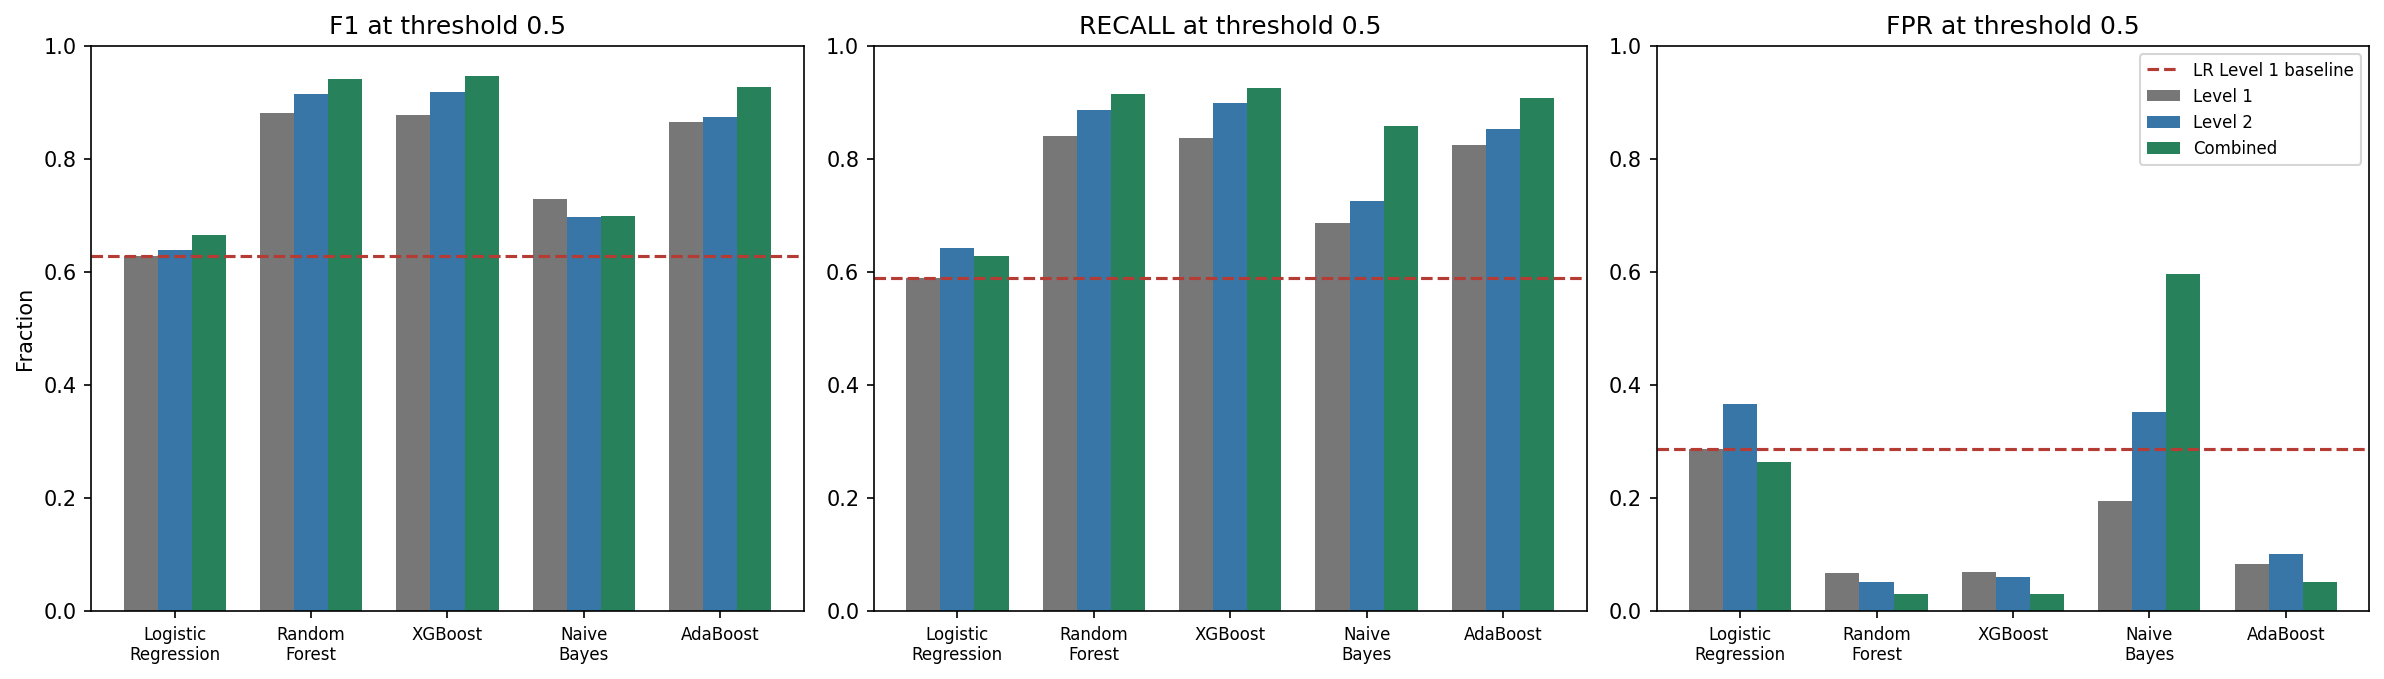

The baseline reached **62.83% F1** and **58.90% recall**, with **411 missed phishing URLs** and **286 false alarms**. **XGBoost / Combined** had the highest observed test F1 (**94.63%**, 95% row-bootstrap interval 93.57%–95.61%), with **92.50% recall** and **3.00% FPR**. It missed 75 of 1,000 phishing URLs and flagged 30 of 1,000 benign URLs. Compared with the baseline, that is 336 fewer misses and 256 fewer false alarms. Its F1 was +31.80 pp above the baseline.

**Random Forest / Combined** followed at 94.19% F1, with 91.60% recall and 2.90% FPR. The difference between these two top observed F1 scores was only 0.44 pp. We treat both as candidates for confirmation; ranking them on an already inspected test split does not establish a reliable winner for future URLs. The highest **training-CV** F1 belonged to XGBoost / Combined (94.29%), so the CV ranking can be distinguished from the observed test ranking.

In [2]:
section(f"""
# Preliminary findings: PhishEvade

**Status:** Preliminary analysis for panel feedback. These results reproduce the existing saved experiment and are subject to data leakage and test reuse described below.

## 1. Evaluation design

We evaluated five classifiers under three feature configurations: Level 1 (3 basic length features), Level 2 (10 obfuscation-aware features), and Combined (all 13). Module 7 performed a stratified 80:20 split and selected hyperparameters using F1 in five-fold GridSearchCV on the 8,000 training rows. For evaluation, we independently loaded the saved models and used the same {meta['n_test']:,} test URLs, consisting of 1,000 benign and 1,000 phishing URLs. We flagged scores at or above 0.5 as phishing and compared the results with the Module 6 Logistic Regression Level 1 baseline. F1 was our main performance measure; recall, false negative rate (FNR), and false positive rate (FPR) showed the operational cost of missed threats and false alarms.

The artifact checks confirmed that all 15 saved model files matched the manifest, and that their confusion matrices reproduced Module 7's recorded results. The separately loaded Module 6 baseline reproduced the Logistic Regression Level 1 reference. These checks establish that the saved models produce the expected outputs on the original test partition. They do not remove the preprocessing and split limitations.
""")
view=m[['classifier','feature_set','accuracy','precision','recall','f1','fpr','fnr','delta_f1_vs_baseline_pp']].copy()
for col in ['accuracy','precision','recall','f1','fpr','fnr']:view[col]=view[col].map(pct)
view['delta_f1_vs_baseline_pp']=view.delta_f1_vs_baseline_pp.map(lambda x:f'{x:+.2f}')
view.columns=['Classifier','Features','Accuracy','Precision','Recall','F1','FPR','FNR','ΔF1 vs LR (pp)']
section('## 2. Full comparison at the 0.5 threshold\n\n'+mdtable(view))
chart('01_feature_comparison.png','F1, recall and FPR for all 15 combinations relative to the Level 1 Logistic Regression baseline.')
section(f"""
The baseline reached **{pct(base.f1)} F1** and **{pct(base.recall)} recall**, with **{int(base.fn)} missed phishing URLs** and **{int(base.fp)} false alarms**. **{label(best)}** had the highest observed test F1 (**{pct(best.f1)}**, 95% row-bootstrap interval {pct(best.f1_ci_low)}–{pct(best.f1_ci_high)}), with **{pct(best.recall)} recall** and **{pct(best.fpr)} FPR**. It missed {int(best.fn)} of 1,000 phishing URLs and flagged {int(best.fp)} of 1,000 benign URLs. Compared with the baseline, that is {int(base.fn-best.fn)} fewer misses and {int(base.fp-best.fp)} fewer false alarms. Its F1 was {pp(best.f1-base.f1)} above the baseline.

**{label(second)}** followed at {pct(second.f1)} F1, with {pct(second.recall)} recall and {pct(second.fpr)} FPR. The difference between these two top observed F1 scores was only {100*(best.f1-second.f1):.2f} pp. We treat both as candidates for confirmation; ranking them on an already inspected test split does not establish a reliable winner for future URLs. The highest **training-CV** F1 belonged to {label(cv_best)} ({pct(cv_best.cv_f1)}), so the CV ranking can be distinguished from the observed test ranking.
""")

## 3. Did the Level 2 features improve detection?

| Classifier | Features | ΔF1 (pp) | 95% ΔF1 interval (pp) | ΔRecall (pp) | ΔFPR (pp) | F1 p (Holm) | FPR reduction p (Holm) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Logistic Regression | Level 2 | 1.12 | -0.93 to +3.23 | 5.3 | 8.0 | 0.845 | 1 |
| Logistic Regression | Combined | 3.66 | +1.48 to +5.93 | 4.0 | -2.3 | 0.012 | 0.985 |
| Random Forest | Level 2 | 3.44 | +1.82 to +5.08 | 4.7 | -1.6 | 0.0048 | 0.733 |
| Random Forest | Combined | 6.05 | +4.67 to +7.38 | 7.6 | -3.7 | 0.0048 | 4.2e-05 |
| XGBoost | Level 2 | 4.01 | +2.45 to +5.61 | 6.3 | -0.9 | 0.0048 | 1 |
| XGBoost | Combined | 6.8 | +5.39 to +8.18 | 8.8 | -3.9 | 0.0048 | 3.69e-05 |
| Naive Bayes | Level 2 | -3.17 | -5.36 to -1.07 | 3.9 | 15.8 | 0.0272 | 1 |
| Naive Bayes | Combined | -3.03 | -4.97 to -1.16 | 17.3 | 40.3 | 0.014 | 1 |
| AdaBoost | Level 2 | 0.87 | -0.96 to +2.76 | 2.8 | 1.7 | 0.845 | 1 |
| AdaBoost | Combined | 6.27 | +4.81 to +7.72 | 8.3 | -3.3 | 0.0048 | 0.0013 |

The feature effect is best assessed **within the same classifier**. Combined increased observed F1 in **4 of 5** classifiers, while Level 2 alone increased it in **4 of 5**. Combined Random Forest, XGBoost, and AdaBoost each improved F1 and reduced FPR relative to their own Level 1 versions, with Holm-adjusted p-values below 0.05 for both tests on this split. Logistic Regression illustrates why F1 and FPR must be read together: Level 2 alone changed F1 by +1.12 pp but changed FPR by +8.00 pp. The combined version reduced FPR to 26.30% and improved F1 to 66.49%.

Gaussian Naïve Bayes was the exception for Combined: recall rose from 68.60% to 85.90%, but FPR rose to 59.70%, lowering F1. One possible explanation is that related length, count, and ratio features do not behave as independent signals under Gaussian Naïve Bayes. We did not test that explanation directly. The observed pattern supports using the engineered features with suitable classifiers; it does not show that adding them always improves detection.

The paired bootstrap intervals use the same resampled test rows for each model. They describe the precision of observed F1 differences on this dataset. The paired F1 randomization, overall-error, and benign FPR tests use Holm correction across the 24 contrasts per test family. They are conditional on this split and are not tests of leakage-free or temporal generalization. The F1 intervals are exploratory and unadjusted for multiple comparisons.

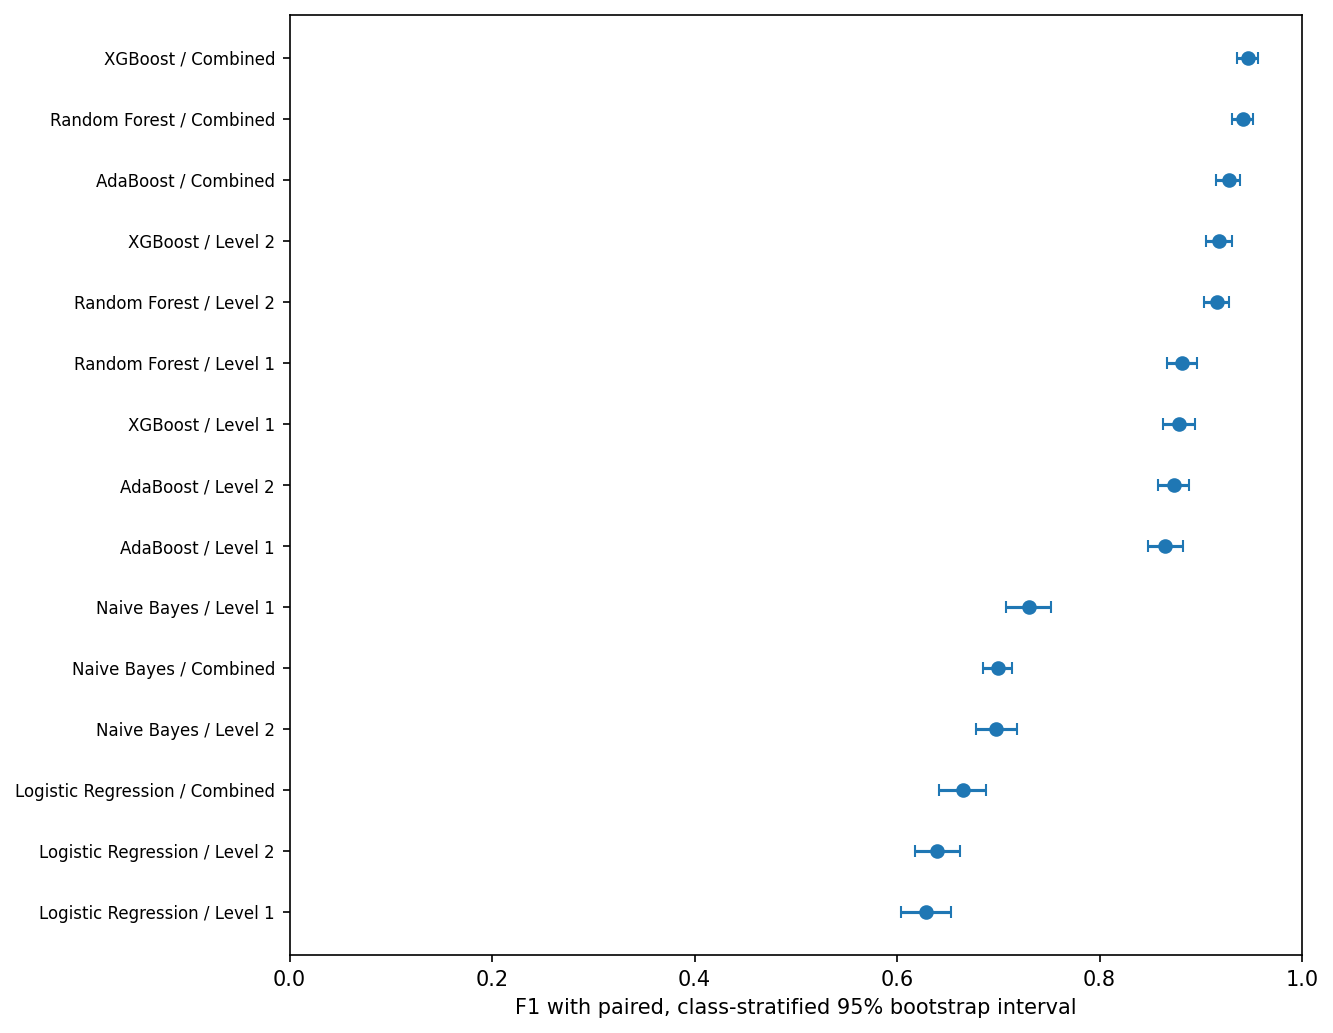

In [3]:
abl=[]
for c in C:
    local=m[m.classifier==c].set_index('feature_set')
    for fs in F[1:]:
        a=local.loc[fs];b=local.loc['Level 1'];d=p[(p.combination==a.combination)&(p.reference==b.combination)&p.family.str.startswith('within')].iloc[0]
        abl.append({'Classifier':c,'Features':fs,'ΔF1 (pp)':round(d.delta_f1_pp,2),
            '95% ΔF1 interval (pp)':f'{d.delta_f1_ci_low_pp:+.2f} to {d.delta_f1_ci_high_pp:+.2f}',
            'ΔRecall (pp)':round(100*(a.recall-b.recall),2),'ΔFPR (pp)':round(d.delta_fpr_pp,2),
            'F1 p (Holm)':f'{d.f1_permutation_p_holm:.3g}','FPR reduction p (Holm)':f'{d.fpr_reduction_p_holm:.3g}'})
a=pd.DataFrame(abl);a.to_csv(OUT/'feature_ablation_summary.csv',index=False)
section('## 3. Did the Level 2 features improve detection?\n\n'+mdtable(a))
comp=a[a.Features=='Combined'];only=a[a.Features=='Level 2']
nb=m[m.classifier=='Naive Bayes'].set_index('feature_set');lc=m[m.classifier=='Logistic Regression'].set_index('feature_set')
section(f"""
The feature effect is best assessed **within the same classifier**. Combined increased observed F1 in **{(comp['ΔF1 (pp)']>0).sum()} of 5** classifiers, while Level 2 alone increased it in **{(only['ΔF1 (pp)']>0).sum()} of 5**. Combined Random Forest, XGBoost, and AdaBoost each improved F1 and reduced FPR relative to their own Level 1 versions, with Holm-adjusted p-values below 0.05 for both tests on this split. Logistic Regression illustrates why F1 and FPR must be read together: Level 2 alone changed F1 by {pp(lc.loc['Level 2','f1']-lc.loc['Level 1','f1'])} but changed FPR by {pp(lc.loc['Level 2','fpr']-lc.loc['Level 1','fpr'])}. The combined version reduced FPR to {pct(lc.loc['Combined','fpr'])} and improved F1 to {pct(lc.loc['Combined','f1'])}.

Gaussian Naïve Bayes was the exception for Combined: recall rose from {pct(nb.loc['Level 1','recall'])} to {pct(nb.loc['Combined','recall'])}, but FPR rose to {pct(nb.loc['Combined','fpr'])}, lowering F1. One possible explanation is that related length, count, and ratio features do not behave as independent signals under Gaussian Naïve Bayes. We did not test that explanation directly. The observed pattern supports using the engineered features with suitable classifiers; it does not show that adding them always improves detection.

The paired bootstrap intervals use the same resampled test rows for each model. They describe the precision of observed F1 differences on this dataset. The paired F1 randomization, overall-error, and benign FPR tests use Holm correction across the 24 contrasts per test family. They are conditional on this split and are not tests of leakage-free or temporal generalization. The F1 intervals are exploratory and unadjusted for multiple comparisons.
""")
chart('02_f1_intervals.png','Observed hold-out F1 with 95% class-stratified bootstrap intervals.')

## 4. Evasion indicators and missed URLs

| Slice | Model | Phishing | Benign | Recall | FNR | FPR | FN | FP |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Evasion-indicator proxy | Logistic Regression / Level 1 | 344 | 188 | 70.93% | 29.07% | 19.68% | 100 | 37 |
| Evasion-indicator proxy | XGBoost / Combined | 344 | 188 | 95.06% | 4.94% | 2.66% | 17 | 5 |
| Evasion-indicator proxy | Random Forest / Combined | 344 | 188 | 93.90% | 6.10% | 1.06% | 21 | 2 |
| Domain unseen in training | Logistic Regression / Level 1 | 207 | 749 | 59.42% | 40.58% | 32.71% | 84 | 245 |
| Domain unseen in training | XGBoost / Combined | 207 | 749 | 75.36% | 24.64% | 3.34% | 51 | 25 |
| Domain unseen in training | Random Forest / Combined | 207 | 749 | 72.46% | 27.54% | 3.34% | 57 | 25 |
| Exact URL absent from training | Logistic Regression / Level 1 | 999 | 1000 | 58.96% | 41.04% | 28.60% | 410 | 286 |
| Exact URL absent from training | XGBoost / Combined | 999 | 1000 | 92.49% | 7.51% | 3.00% | 75 | 30 |
| Exact URL absent from training | Random Forest / Combined | 999 | 1000 | 91.59% | 8.41% | 2.90% | 84 | 29 |

The repository does not include collection timestamps or independently labelled evasion-heavy cases. We therefore used an **evasion-indicator proxy** as an exploratory diagnostic: query encoding, redirect or nested URL flags, deep paths/subdomains, or high entropy/token variance relative to the training distribution. It contains 344 phishing and 188 benign test URLs. In this slice, XGBoost / Combined detected **95.06%** of phishing URLs (FNR 4.94%), compared with **90.99%** for its own Level 1 version and **70.93%** for the global baseline. The combined model produced 5 false alarms among these complex benign URLs (FPR 2.66%). Combined Naïve Bayes produced 54 false alarms in the same benign slice (FPR 28.72%), illustrating that complexity is not inherently malicious.

The original split contained 1,044 test URLs whose registered domain also occurred in training, including 1 verbatim repeat after normalization. On the domain-unseen portion (207 phishing and 749 benign), the observed leading model had 75.36% recall and 3.34% FPR, versus 96.97% recall on the 793 phishing URLs from previously seen domains. The gap may reflect differences in the subsets as well as familiarity with the domains. Removing the verbatim repeat gives F1 94.62% for that model. These slices diagnose overlap in the existing split; neither the proxy nor the domain slice is a substitute for testing later, independently labelled samples. Counts and all per-model/per-indicator rates are available in `subset_evaluation.csv`. Defanged, row-indexed false positive and false negative examples are available in `error_examples_defanged.csv`.

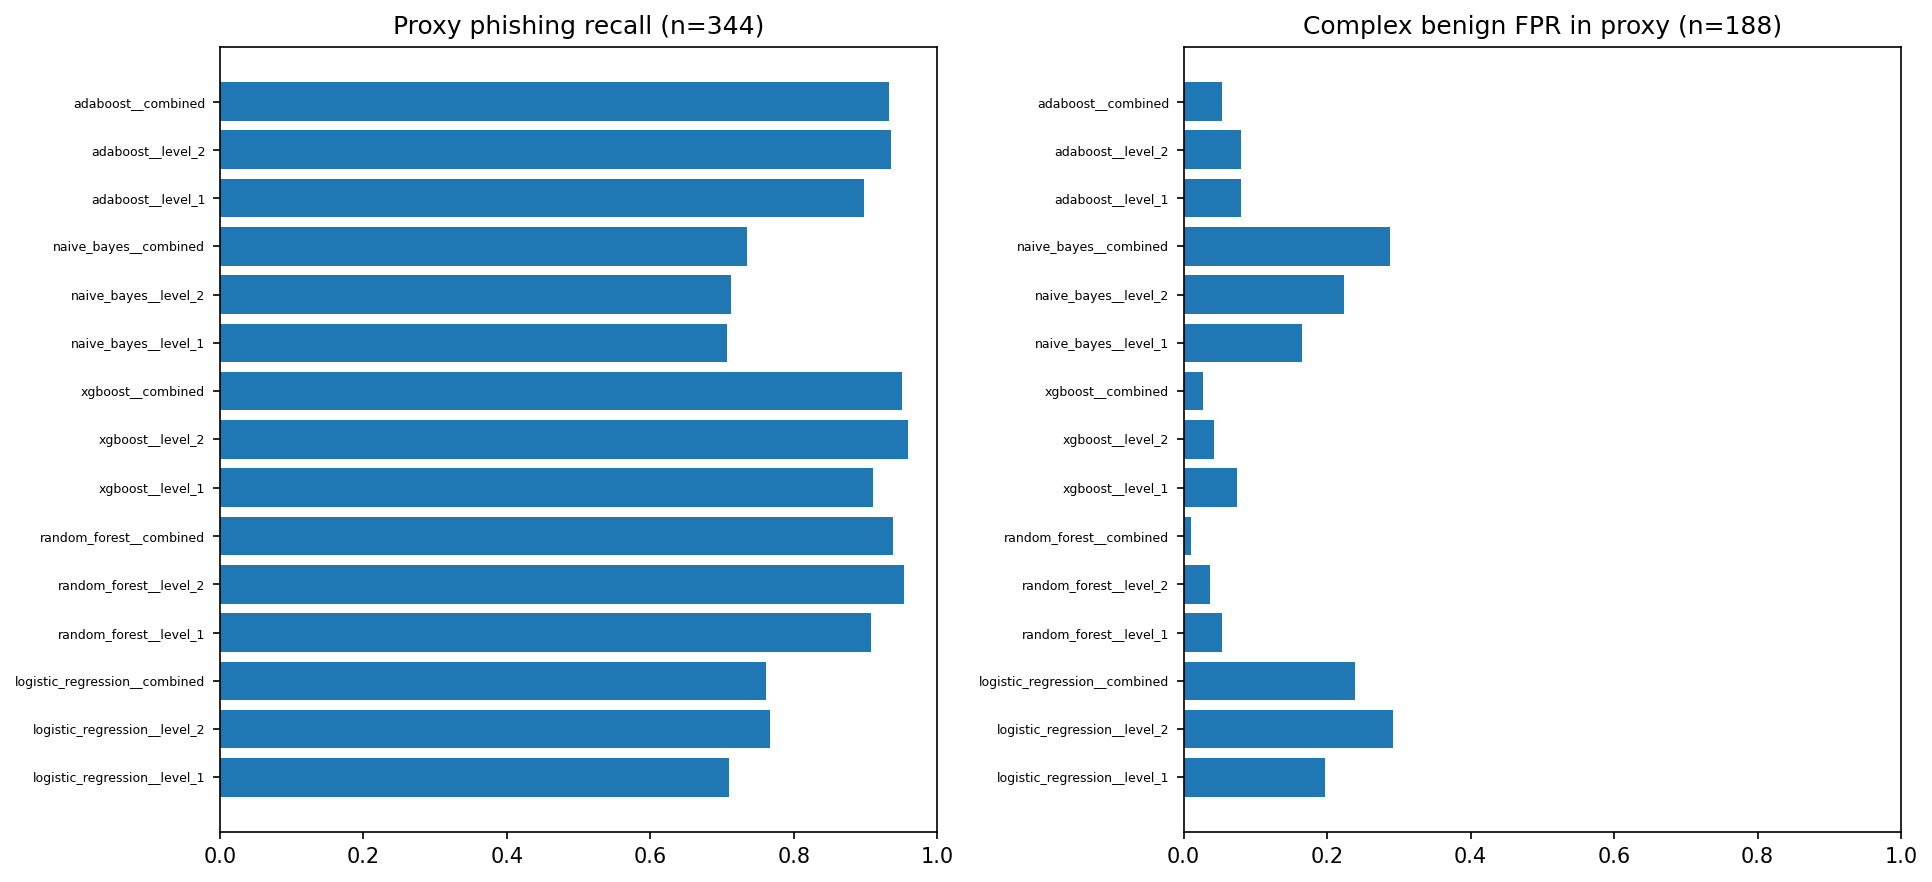

In [4]:
proxy=s[s.slice=='evasion_indicator_proxy'].set_index('combination')
unseen=s[s.slice=='domain_unseen_in_training'].set_index('combination')
exact=s[s.slice=='exact_url_not_in_training'].set_index('combination')
brief=[]
for name,frame in [('Evasion-indicator proxy',proxy),('Domain unseen in training',unseen),('Exact URL absent from training',exact)]:
 for k in [base.name,best.combination,second.combination]:
    z=frame.loc[k];brief.append({'Slice':name,'Model':label(M.loc[k]),'Phishing':int(z.n_phishing),'Benign':int(z.n_benign),
                                'Recall':pct(z.recall),'FNR':pct(z.fnr),'FPR':pct(z.fpr),'FN':int(z.fn),'FP':int(z.fp)})
section('## 4. Evasion indicators and missed URLs\n\n'+mdtable(pd.DataFrame(brief)))
p1=proxy.loc[best.combination];p0=proxy.loc[base.name]
best_l1=m[(m.classifier==best.classifier)&(m.feature_set=='Level 1')].iloc[0];same=proxy.loc[best_l1.combination]
nbp=proxy.loc['naive_bayes__combined'];up=unseen.loc[best.combination]
sp=s[s.slice=='domain_seen_in_training'].set_index('combination').loc[best.combination]
section(f"""
The repository does not include collection timestamps or independently labelled evasion-heavy cases. We therefore used an **evasion-indicator proxy** as an exploratory diagnostic: query encoding, redirect or nested URL flags, deep paths/subdomains, or high entropy/token variance relative to the training distribution. It contains {int(p1.n_phishing)} phishing and {int(p1.n_benign)} benign test URLs. In this slice, {label(best)} detected **{pct(p1.recall)}** of phishing URLs (FNR {pct(p1.fnr)}), compared with **{pct(same.recall)}** for its own Level 1 version and **{pct(p0.recall)}** for the global baseline. The combined model produced {int(p1.fp)} false alarms among these complex benign URLs (FPR {pct(p1.fpr)}). Combined Naïve Bayes produced {int(nbp.fp)} false alarms in the same benign slice (FPR {pct(nbp.fpr)}), illustrating that complexity is not inherently malicious.

The original split contained {int(Q['test URLs whose registered domain occurs in training']):,} test URLs whose registered domain also occurred in training, including {int(Q['test URLs repeated verbatim in training'])} verbatim repeat after normalization. On the domain-unseen portion ({int(up.n_phishing)} phishing and {int(up.n_benign)} benign), the observed leading model had {pct(up.recall)} recall and {pct(up.fpr)} FPR, versus {pct(sp.recall)} recall on the {int(sp.n_phishing)} phishing URLs from previously seen domains. The gap may reflect differences in the subsets as well as familiarity with the domains. Removing the verbatim repeat gives F1 {pct(exact.loc[best.combination,'f1'])} for that model. These slices diagnose overlap in the existing split; neither the proxy nor the domain slice is a substitute for testing later, independently labelled samples. Counts and all per-model/per-indicator rates are available in `subset_evaluation.csv`. Defanged, row-indexed false positive and false negative examples are available in `error_examples_defanged.csv`.
""")
chart('09_proxy_subset.png','Phishing recall and benign false positive rate within the evasion-indicator proxy.')

,error_type,row_index,probability,evasion_indicator_proxy,url_length,path_depth,domain_entropy,query_encoding_ratio
128,FP,9624,0.8198,False,25.0,1.0,3.6464,0.0
129,FP,1706,0.5457,False,29.0,1.0,3.3919,0.0
130,FP,4024,0.9373,False,52.0,3.0,3.8333,0.0
136,FN,253,0.0056,False,15.0,0.0,3.0566,0.0
137,FN,938,0.0021,False,5.0,0.0,2.3219,0.0
138,FN,1994,0.0019,False,16.0,0.0,3.3278,0.0


## 5. Feature importance, fit, and threshold sensitivity

Top five shuffled features for the leading Combined model, measured by decrease in test F1:

| feature | level | f1_drop_mean | f1_drop_std |
| --- | --- | --- | --- |
| path_length | Level 1 | 0.1595 | 0.0018 |
| domain_length | Level 1 | 0.0849 | 0.0027 |
| token_variance | Level 2 | 0.0545 | 0.0066 |
| url_length | Level 1 | 0.0456 | 0.0011 |
| path_depth | Level 2 | 0.0408 | 0.0056 |

For XGBoost / Combined, shuffling **path_length** caused the largest average F1 drop (15.95 pp). Both lexical and obfuscation-aware columns are inspected in the permutation table. Shuffling measures how the fitted model used the feature in this test set; it does not identify a causal signal or reliably separate contributions of correlated columns. The largest resubstitution-to-test F1 gap was 8.09 pp for Random Forest / Level 2; the resubstitution score is an optimistic fit diagnostic. The leading model had CV F1 94.29% and test F1 94.63%. Close scores are useful as a consistency check but cannot rule out shared-domain or preprocessing effects.

At the stored training-derived threshold (0.44), the leading model's observed recall was 93.10% and FPR was 3.80%, versus 92.50% and 3.00% at 0.5. This sensitivity comparison is secondary; we retained 0.5 as the proposal's primary rule. The model's ROC-AUC was 0.9800, average precision 0.9840, and Brier score 0.0444. The output score estimates **phishing** likelihood under the model. The experiment does not establish that it measures intent to evade or that its probabilities will be calibrated at real-world phishing prevalence.

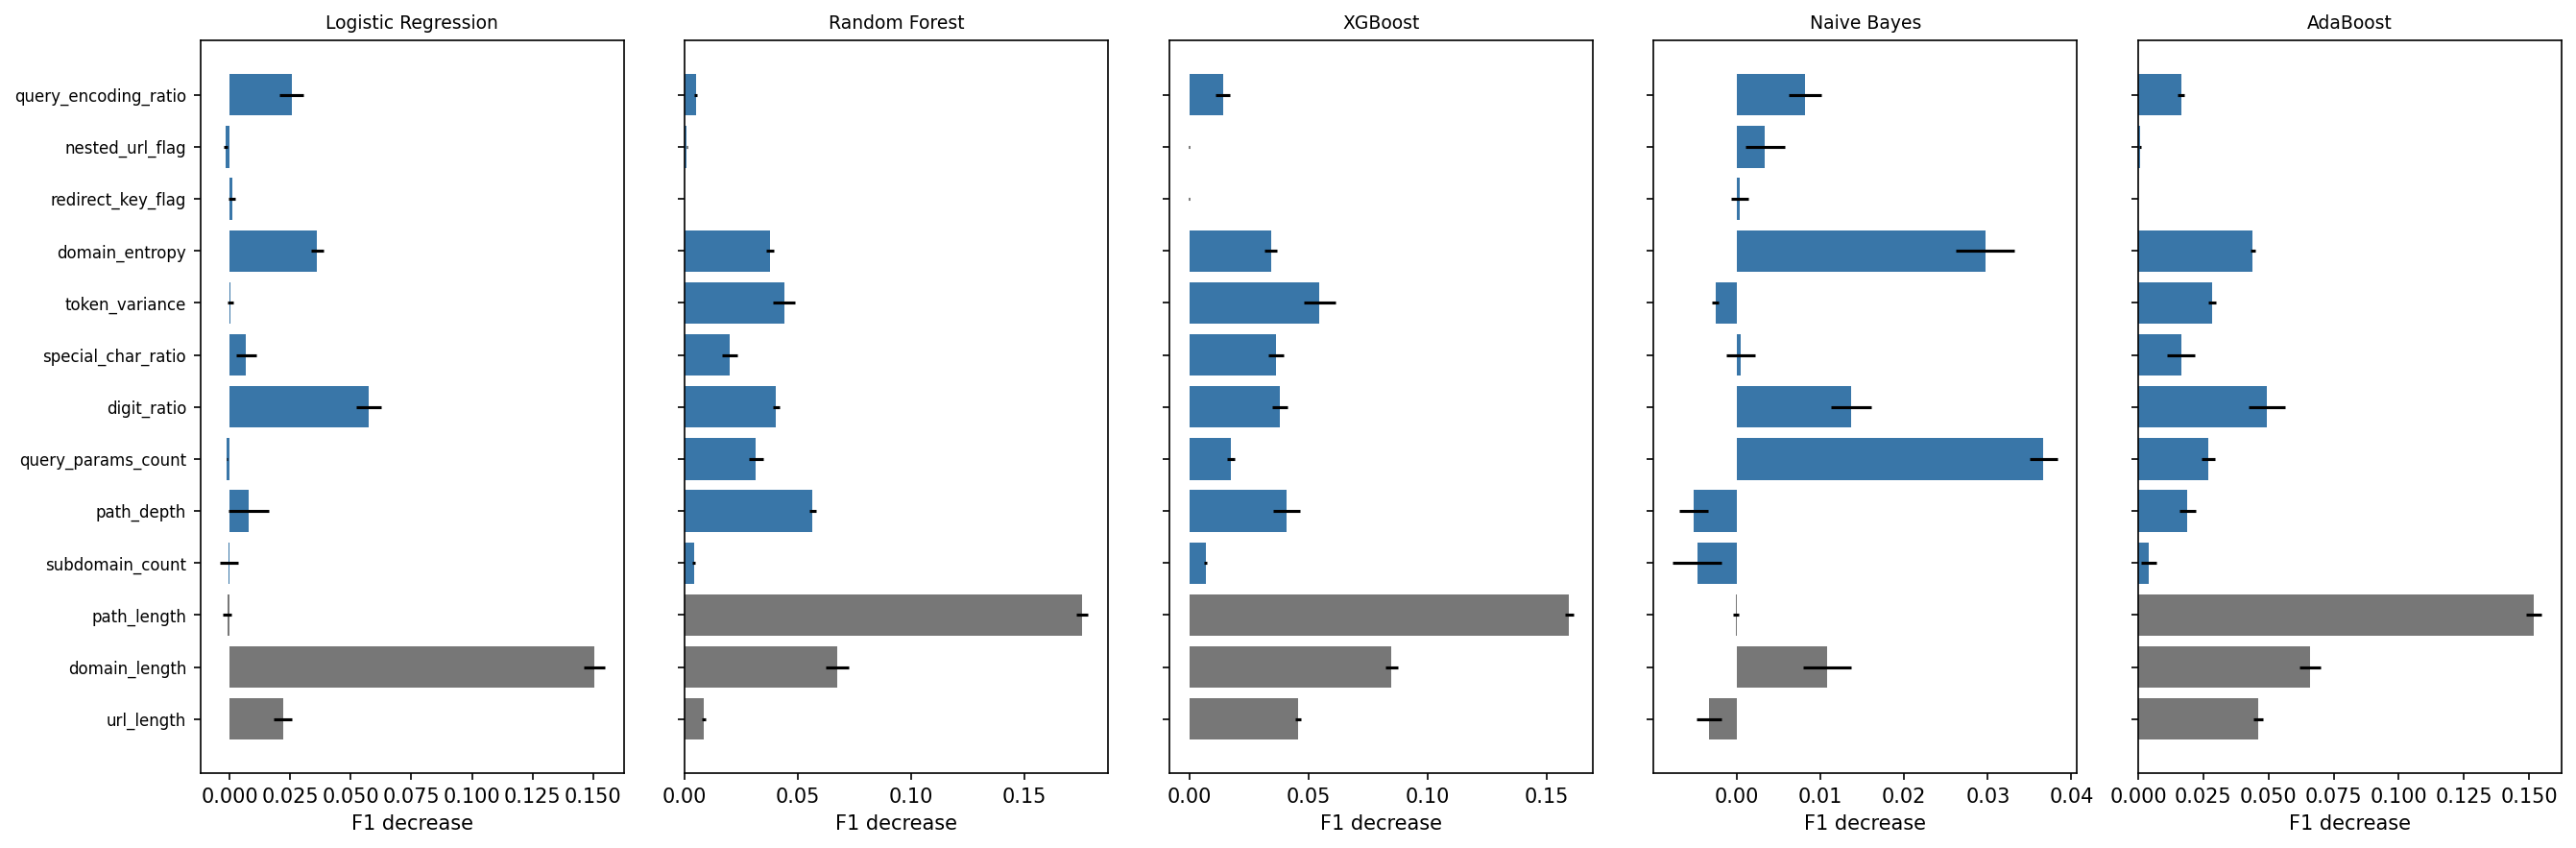

In [5]:
# Explain concrete error patterns with aggregate counts; this avoids exposing active URLs.
errors=read('error_examples_defanged')
v=errors[errors.combination==best.combination]
showcols=['error_type','row_index','probability','evasion_indicator_proxy','url_length','path_depth','domain_entropy','query_encoding_ratio']
display(v[showcols].groupby('error_type').head(3).round(4))
imp_top=imp[imp.classifier==best.classifier].nlargest(5,'f1_drop_mean')
imp_display=imp_top[['feature','level','f1_drop_mean','f1_drop_std']].round(4)
section('## 5. Feature importance, fit, and threshold sensitivity\n\n'+
        'Top five shuffled features for the leading Combined model, measured by decrease in test F1:\n\n'+mdtable(imp_display))
tr=t.set_index('combination').loc[best.combination]
large_gap=m.loc[m.train_minus_test_f1.idxmax()]
section(f"""
For {label(best)}, shuffling **{imp_top.iloc[0].feature}** caused the largest average F1 drop ({100*imp_top.iloc[0].f1_drop_mean:.2f} pp). Both lexical and obfuscation-aware columns are inspected in the permutation table. Shuffling measures how the fitted model used the feature in this test set; it does not identify a causal signal or reliably separate contributions of correlated columns. The largest resubstitution-to-test F1 gap was {100*large_gap.train_minus_test_f1:.2f} pp for {label(large_gap)}; the resubstitution score is an optimistic fit diagnostic. The leading model had CV F1 {pct(best.cv_f1)} and test F1 {pct(best.f1)}. Close scores are useful as a consistency check but cannot rule out shared-domain or preprocessing effects.

At the stored training-derived threshold ({tr.threshold:.2f}), the leading model's observed recall was {pct(tr.recall)} and FPR was {pct(tr.fpr)}, versus {pct(best.recall)} and {pct(best.fpr)} at 0.5. This sensitivity comparison is secondary; we retained 0.5 as the proposal's primary rule. The model's ROC-AUC was {best.roc_auc:.4f}, average precision {best.average_precision:.4f}, and Brier score {best.brier:.4f}. The output score estimates **phishing** likelihood under the model. The experiment does not establish that it measures intent to evade or that its probabilities will be calibrated at real-world phishing prevalence.
""")
chart('06_permutation_importance.png','Permutation importance for the five Combined models, three shuffled repetitions.')

## 6. Resource tradeoffs

| Model | Training s (original) | Peak RSS MiB (original) | Original mean ms/URL | Rerun mean / p95 ms/URL | Model MiB | Extraction s / 10k (original) |
| --- | --- | --- | --- | --- | --- | --- |
| Logistic Regression / Level 1 | 0.95 | 253.8 | 0.054 | 0.037 / 0.063 | 0.001 | 0.083 |
| XGBoost / Combined | 42.45 | 303.4 | 0.451 | 0.189 / 0.314 | 0.826 | 0.396 |
| Random Forest / Combined | 154.33 | 288.5 | 7.801 | 5.523 / 6.229 | 29.330 | 0.396 |
| AdaBoost / Combined | 89.27 | 295.6 | 9.217 | 8.309 / 11.598 | 0.282 | 0.396 |

XGBoost / Combined took 42.45 s for the original grid search and refit, compared with 154.33 s for Random Forest / Combined. Their original model-only mean inference times were 0.451 and 7.801 ms per URL, respectively. In the separate evaluation runtime, the observed means were 0.189 and 5.523 ms per URL. The models occupied 0.826 and 29.330 MiB on disk. Training peak RSS includes the original Python process and previously retained models; it is not the memory attributable solely to each fitted classifier. Extraction times come from the rounded Module 3–4 profile; they are not new measurements and do not include browsing or deployment. The timings support a comparison of this offline experiment. They cannot establish browser, gateway, or deep-learning performance.

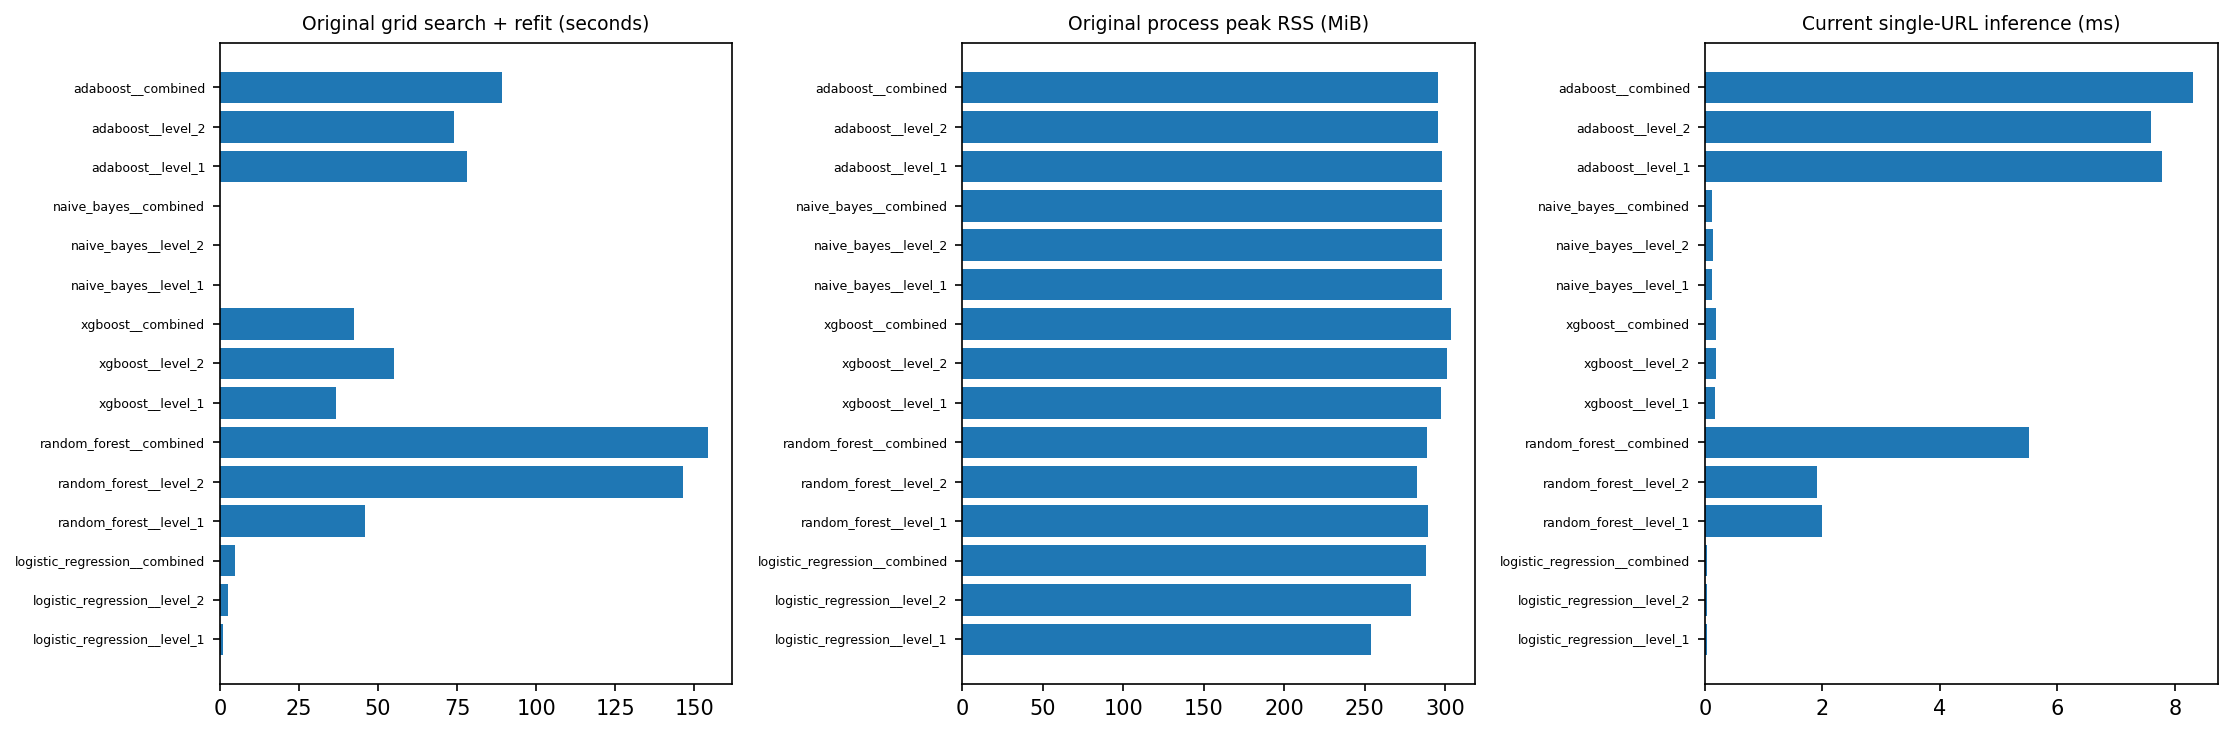

In [6]:
resource_view=[]
for k in [base.name,best.combination,second.combination,'adaboost__combined']:
    z=R.loc[k]
    resource_view.append({'Model':label(M.loc[k]),'Training s (original)':f'{z.training_time_s_historical:.2f}',
     'Peak RSS MiB (original)':f'{z.training_peak_rss_mb_historical:.1f}',
     'Original mean ms/URL':f'{z.inference_ms_per_url_historical:.3f}',
     'Rerun mean / p95 ms/URL':f'{z.inference_mean_ms_current:.3f} / {z.inference_p95_ms_current:.3f}',
     'Model MiB':f'{z.model_size_mb:.3f}',
     'Extraction s / 10k (original)':f'{z.extraction_10000_urls_s_historical_rounded:.3f}'})
section('## 6. Resource tradeoffs\n\n'+mdtable(pd.DataFrame(resource_view)))
best_cost=R.loc[best.combination];second_cost=R.loc[second.combination]
section(f"""
{label(best)} took {best_cost.training_time_s_historical:.2f} s for the original grid search and refit, compared with {second_cost.training_time_s_historical:.2f} s for {label(second)}. Their original model-only mean inference times were {best_cost.inference_ms_per_url_historical:.3f} and {second_cost.inference_ms_per_url_historical:.3f} ms per URL, respectively. In the separate evaluation runtime, the observed means were {best_cost.inference_mean_ms_current:.3f} and {second_cost.inference_mean_ms_current:.3f} ms per URL. The models occupied {best_cost.model_size_mb:.3f} and {second_cost.model_size_mb:.3f} MiB on disk. Training peak RSS includes the original Python process and previously retained models; it is not the memory attributable solely to each fitted classifier. Extraction times come from the rounded Module 3–4 profile; they are not new measurements and do not include browsing or deployment. The timings support a comparison of this offline experiment. They cannot establish browser, gateway, or deep-learning performance.
""")
chart('08_resource_profile.png','Historical training cost and current model-only inference latency for the 15 combinations.')

In [7]:
section(f"""
## 7. Preliminary conclusion and work before final evaluation

In this balanced dataset, the leading Combined models showed better observed F1 and fewer missed phishing URLs than their lexical-only versions. The results support the preliminary finding that the Level 2 features add useful information to the lexical features for some classifiers. The Naïve Bayes results show that this gain is model-dependent and can come with a high cost in false alarms. We would carry {label(best)} and {label(second)} forward for confirmation, using F1, recall, FPR, and resource costs together to assess the tradeoff.

These results should not yet be presented as final evidence. Module 5 estimated scaling parameters from all 10,000 URLs before the split, allowing test and validation rows to influence preprocessing. Modules 6 and 7 inspected the test results, and Module 2 removed duplicates before normalization, leaving {int(Q['duplicate normalized URLs'])} duplicates after normalization. The source rankings/feeds and balanced class ratio also differ from live traffic, so precision here should not be extrapolated to deployment. Full-string lowercasing can change case-sensitive paths and encoded payloads. The milestone form lists a six/seven allocation while the final proposal's explicit 3/10 definition and the repository use three lengths and ten obfuscation-aware features. The panel should confirm the 3/10 allocation and the proposal's Table 4.1 definitions before the final run.

Before final evaluation, we should deduplicate after normalization, preserve timestamps and source provenance, and verify feature definitions against representative encoded examples. We should fit scaling inside each training fold and persist the full pipelines. We should then evaluate once on a later, independently held-out set with validated evasion labels and domain separation, reporting detection and false alarm rates with their support. This will let us test whether the gains persist on newer examples and whether the observed resource costs remain acceptable on the target hardware.

**Evidence trail:** `performance_comparison_15.csv`, `paired_comparisons.csv`, `subset_evaluation.csv`, `resource_comparison.csv`, `tuned_threshold_sensitivity.csv`, `artifact_verification.csv`, and `evaluation_metadata.json` in `Results/milestone8/`. All plots and primary scores use the original saved models. The evaluation commit was `{meta['source_commit_reviewed']}`.
""")
report='\n\n'.join(sections)+'\n'
(OUT/'preliminary_findings_draft.md').write_text(report,encoding='utf-8')
assert len(sections)>=14 and 'Preliminary conclusion' in report and 'Full comparison' in report
print('Milestone 9 complete: draft and ablation table saved to',OUT)

Milestone 9 complete: draft and ablation table saved to /workspace/scratch/e3e5f7f7f0e0/full_repo/Results/milestone9


## 7. Preliminary conclusion and work before final evaluation

In this balanced dataset, the leading Combined models showed better observed F1 and fewer missed phishing URLs than their lexical-only versions. The results support the preliminary finding that the Level 2 features add useful information to the lexical features for some classifiers. The Naïve Bayes results show that this gain is model-dependent and can come with a high cost in false alarms. We would carry XGBoost / Combined and Random Forest / Combined forward for confirmation, using F1, recall, FPR, and resource costs together to assess the tradeoff.

These results should not yet be presented as final evidence. Module 5 estimated scaling parameters from all 10,000 URLs before the split, allowing test and validation rows to influence preprocessing. Modules 6 and 7 inspected the test results, and Module 2 removed duplicates before normalization, leaving 7 duplicates after normalization. The source rankings/feeds and balanced class ratio also differ from live traffic, so precision here should not be extrapolated to deployment. Full-string lowercasing can change case-sensitive paths and encoded payloads. The milestone form lists a six/seven allocation while the final proposal's explicit 3/10 definition and the repository use three lengths and ten obfuscation-aware features. The panel should confirm the 3/10 allocation and the proposal's Table 4.1 definitions before the final run.

Before final evaluation, we should deduplicate after normalization, preserve timestamps and source provenance, and verify feature definitions against representative encoded examples. We should fit scaling inside each training fold and persist the full pipelines. We should then evaluate once on a later, independently held-out set with validated evasion labels and domain separation, reporting detection and false alarm rates with their support. This will let us test whether the gains persist on newer examples and whether the observed resource costs remain acceptable on the target hardware.

**Evidence trail:** `performance_comparison_15.csv`, `paired_comparisons.csv`, `subset_evaluation.csv`, `resource_comparison.csv`, `tuned_threshold_sensitivity.csv`, `artifact_verification.csv`, and `evaluation_metadata.json` in `Results/milestone8/`. All plots and primary scores use the original saved models. The evaluation commit was `1178f6aa41318b34f7b7c8522cf1f867cb74f06b`.